# Point-count products: fits in the logarithmic coordinate

Implementation for Section 5 of [Bucur–Kedlaya–Sheth, arXiv:2608.18014](https://arxiv.org/pdf/2608.18014), using the four curves in the [original repository](https://github.com/arshaysheth24/Code-for-plots-of-products-of-point-counts-for-higher-genus-curves-over-finite-fields-).

**Run all cells in a Python 3 or SageMath notebook.** Only NumPy and Matplotlib are required for the cached-data calculation. All 750-prime point-count data and fitting functions are embedded in this notebook; no companion files are needed. Optional fresh SageMath computation is at the end.

Put $t=\log\log P$ and $Y(P)=\sum_{p\le P,\,p\notin S_X}\log(N_p/p)$. The main fit minimizes
\[
\int_{\log\log 31}^{\log\log 5693}
\bigl(Y(e^{e^t})-\alpha-\beta t\bigr)^2\,dt.
\]
The code integrates the actual cumulative step function exactly. The red dots are 200 snapshots equally spaced in $t$; the blue line is the exact integral fit. The dashed grey line gives every retained prime equal weight, on the **same** fitting interval.

“Weighted by log log” means integration against $d(\log\log P)=dP/(P\log P)$, not multiplication by $\log\log p$. Geometrically spaced $P$ values instead approximate weighting by $d(\log P)$; that alternative is also implemented.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

"""Fits for log point-count products versus log log of the cutoff.

Requires NumPy; works in Python and SageMath. All logarithms are natural.
The input y_values are cumulative sums, including contributions before the
fitting window. They are right-continuous step values at x_values.
"""

import numpy as np


def _data(x_values, y_values, xmin, xmax):
    x = np.asarray(x_values, dtype=float)
    y = np.asarray(y_values, dtype=float)
    if x.ndim != 1 or y.shape != x.shape or len(x) < 2:
        raise ValueError("Use two equal-length one-dimensional arrays (length >= 2).")
    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        raise ValueError("All input values must be finite.")
    if not np.all(np.diff(x) > 0):
        raise ValueError("x_values must be strictly increasing; do not silently sort.")
    a = float(x[0] if xmin is None else xmin)
    b = float(x[-1] if xmax is None else xmax)
    if not (np.isfinite(a) and np.isfinite(b) and x[0] <= a < b <= x[-1]):
        raise ValueError("Require x_values[0] <= xmin < xmax <= x_values[-1].")
    return x, y, a, b


def _ols(x, y):
    if len(x) < 2 or np.ptp(x) == 0:
        raise ValueError("The fit needs at least two distinct horizontal coordinates.")
    xbar, ybar = float(np.mean(x)), float(np.mean(y))
    centered = x - xbar
    slope = float(np.dot(centered, y - ybar) / np.dot(centered, centered))
    intercept = ybar - slope * xbar
    return {"slope": slope, "intercept": intercept,
            "rmse": float(np.sqrt(np.mean((y - slope*x - intercept)**2))),
            "n_observations": int(len(x))}


def prime_fit(x_values, y_values, xmin=None, xmax=None):
    """Original equal-per-prime OLS, restricted to a stated fitting interval."""
    x, y, a, b = _data(x_values, y_values, xmin, xmax)
    keep = (x >= a) & (x <= b)
    return {**_ols(x[keep], y[keep]), "method": "equal per prime"}


def snapshot_fit(x_values, y_values, xmin=None, xmax=None, n=200,
                 spacing="loglog"):
    """Sample the cumulative step function at prescribed cutoff locations.

    spacing='loglog': equally spaced log log P; approaches integral_fit.
    spacing='log':    equally spaced log P (geometrically spaced P);
                      approaches a DIFFERENT regression, using d(log P).

    Distinct cutoffs may have the same value: retain these observations.
    Only the recorded snapshots are thinned; the product uses every prime.
    """
    x, y, a, b = _data(x_values, y_values, xmin, xmax)
    if isinstance(n, bool) or int(n) != n or n < 2:
        raise ValueError("n must be an integer >= 2.")
    if spacing == "loglog":
        grid = np.linspace(a, b, int(n))
    elif spacing == "log":
        grid = np.log(np.linspace(np.exp(a), np.exp(b), int(n)))
    else:
        raise ValueError("spacing must be 'loglog' or 'log'.")
    grid[0], grid[-1] = a, b
    indices = np.searchsorted(x, grid, side="right") - 1
    values = y[indices]
    return {**_ols(grid, values), "method": "snapshots uniform in " + spacing,
            "x": grid, "y": values, "prime_indices": indices}


def integral_fit(x_values, y_values, xmin=None, xmax=None):
    """Exactly minimize integral_a^b (y(x) - intercept - slope*x)^2 dx.

    y(x) is constant after each retained prime until the next retained prime.
    Excluded primes give no jump. The upper-endpoint value alone has zero
    integral weight. No interpolation, quadrature, or snapshot count is used.
    """
    x, y, a, b = _data(x_values, y_values, xmin, xmax)
    breaks = np.concatenate(([a], x[(x > a) & (x < b)], [b]))
    left, right = breaks[:-1], breaks[1:]
    widths = right - left
    midpoints = left + widths/2
    # Left endpoints are stored prime coordinates or the exact lower cutoff;
    # right-continuous lookup includes the jump at a retained prime.
    levels = y[np.searchsorted(x, left, side="right") - 1]
    length = b - a
    center = a + length/2
    mean_y = float(np.dot(widths, levels) / length)
    slope = float(12*np.sum(widths*(midpoints-center)*(levels-mean_y))/length**3)
    intercept = mean_y - slope*center
    # Integrate the residual square exactly on each constant step.
    residual_at_midpoint = levels - (mean_y + slope*(midpoints-center))
    mse = np.sum(widths*(residual_at_midpoint**2 + slope**2*widths**2/12))/length
    return {"slope": slope, "intercept": intercept,
            "rmse": float(np.sqrt(max(0.0, mse))),
            "method": "exact integral in loglog P", "n_intervals": len(widths)}


def values_from_counts(primes, counts):
    """Return horizontal coordinates and stable cumulative log products."""
    p = np.asarray(primes, dtype=float)
    counts = np.asarray(counts, dtype=float)
    if p.ndim != 1 or p.shape != counts.shape or len(p) < 2:
        raise ValueError("Use matching prime and count arrays of length >= 2.")
    if not np.all(np.isfinite(p)) or not np.all(np.isfinite(counts)):
        raise ValueError("Primes and counts must be finite.")
    if np.any(p <= 1) or np.any(counts <= 0) or np.any(np.diff(p) <= 0):
        raise ValueError("Require increasing primes > 1 and positive counts.")
    return np.log(np.log(p)), np.cumsum(np.log1p((counts-p)/p))


def compare_fits(primes, counts, pmin=31, pmax=5693, snapshots=200):
    """Compare all methods on exactly the same interval."""
    x, y = values_from_counts(primes, counts)
    a, b = np.log(np.log([float(pmin), float(pmax)]))
    return {
        "prime": prime_fit(x, y, a, b),
        "integral": integral_fit(x, y, a, b),
        "loglog_snapshots": snapshot_fit(x, y, a, b, snapshots, "loglog"),
        "log_snapshots": snapshot_fit(x, y, a, b, snapshots, "log"),
    }


EXAMPLES = [{'number': 1, 'label': '440509.a.440509.1', 'expected': 4, 'f': [6, 9, 0, -5, -1, 1], 'h': [1, 1, 0, 1], 'bad': [440509]}, {'number': 2, 'label': '277.a.277.1', 'expected': 0, 'f': [0, -1, -1], 'h': [1, 1, 1, 1], 'bad': [277]}, {'number': 3, 'label': '504.a.27216.1', 'expected': -1, 'f': [21, 0, 15, 0, 3], 'h': [0, 1, 0, 1], 'bad': [2, 3, 7]}, {'number': 4, 'label': '400.a.409600.1', 'expected': -2, 'f': [1, 0, 4, 0, 4, 0, 1], 'h': [], 'bad': [2, 5]}]
DATA = {'1': {'primes': [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97, 101, 103, 107, 109, 113, 127, 131, 137, 139, 149, 151, 157, 163, 167, 173, 179, 181, 191, 193, 197, 199, 211, 223, 227, 229, 233, 239, 241, 251, 257, 263, 269, 271, 277, 281, 283, 293, 307, 311, 313, 317, 331, 337, 347, 349, 353, 359, 367, 373, 379, 383, 389, 397, 401, 409, 419, 421, 431, 433, 439, 443, 449, 457, 461, 463, 467, 479, 487, 491, 499, 503, 509, 521, 523, 541, 547, 557, 563, 569, 571, 577, 587, 593, 599, 601, 607, 613, 617, 619, 631, 641, 643, 647, 653, 659, 661, 673, 677, 683, 691, 701, 709, 719, 727, 733, 739, 743, 751, 757, 761, 769, 773, 787, 797, 809, 811, 821, 823, 827, 829, 839, 853, 857, 859, 863, 877, 881, 883, 887, 907, 911, 919, 929, 937, 941, 947, 953, 967, 971, 977, 983, 991, 997, 1009, 1013, 1019, 1021, 1031, 1033, 1039, 1049, 1051, 1061, 1063, 1069, 1087, 1091, 1093, 1097, 1103, 1109, 1117, 1123, 1129, 1151, 1153, 1163, 1171, 1181, 1187, 1193, 1201, 1213, 1217, 1223, 1229, 1231, 1237, 1249, 1259, 1277, 1279, 1283, 1289, 1291, 1297, 1301, 1303, 1307, 1319, 1321, 1327, 1361, 1367, 1373, 1381, 1399, 1409, 1423, 1427, 1429, 1433, 1439, 1447, 1451, 1453, 1459, 1471, 1481, 1483, 1487, 1489, 1493, 1499, 1511, 1523, 1531, 1543, 1549, 1553, 1559, 1567, 1571, 1579, 1583, 1597, 1601, 1607, 1609, 1613, 1619, 1621, 1627, 1637, 1657, 1663, 1667, 1669, 1693, 1697, 1699, 1709, 1721, 1723, 1733, 1741, 1747, 1753, 1759, 1777, 1783, 1787, 1789, 1801, 1811, 1823, 1831, 1847, 1861, 1867, 1871, 1873, 1877, 1879, 1889, 1901, 1907, 1913, 1931, 1933, 1949, 1951, 1973, 1979, 1987, 1993, 1997, 1999, 2003, 2011, 2017, 2027, 2029, 2039, 2053, 2063, 2069, 2081, 2083, 2087, 2089, 2099, 2111, 2113, 2129, 2131, 2137, 2141, 2143, 2153, 2161, 2179, 2203, 2207, 2213, 2221, 2237, 2239, 2243, 2251, 2267, 2269, 2273, 2281, 2287, 2293, 2297, 2309, 2311, 2333, 2339, 2341, 2347, 2351, 2357, 2371, 2377, 2381, 2383, 2389, 2393, 2399, 2411, 2417, 2423, 2437, 2441, 2447, 2459, 2467, 2473, 2477, 2503, 2521, 2531, 2539, 2543, 2549, 2551, 2557, 2579, 2591, 2593, 2609, 2617, 2621, 2633, 2647, 2657, 2659, 2663, 2671, 2677, 2683, 2687, 2689, 2693, 2699, 2707, 2711, 2713, 2719, 2729, 2731, 2741, 2749, 2753, 2767, 2777, 2789, 2791, 2797, 2801, 2803, 2819, 2833, 2837, 2843, 2851, 2857, 2861, 2879, 2887, 2897, 2903, 2909, 2917, 2927, 2939, 2953, 2957, 2963, 2969, 2971, 2999, 3001, 3011, 3019, 3023, 3037, 3041, 3049, 3061, 3067, 3079, 3083, 3089, 3109, 3119, 3121, 3137, 3163, 3167, 3169, 3181, 3187, 3191, 3203, 3209, 3217, 3221, 3229, 3251, 3253, 3257, 3259, 3271, 3299, 3301, 3307, 3313, 3319, 3323, 3329, 3331, 3343, 3347, 3359, 3361, 3371, 3373, 3389, 3391, 3407, 3413, 3433, 3449, 3457, 3461, 3463, 3467, 3469, 3491, 3499, 3511, 3517, 3527, 3529, 3533, 3539, 3541, 3547, 3557, 3559, 3571, 3581, 3583, 3593, 3607, 3613, 3617, 3623, 3631, 3637, 3643, 3659, 3671, 3673, 3677, 3691, 3697, 3701, 3709, 3719, 3727, 3733, 3739, 3761, 3767, 3769, 3779, 3793, 3797, 3803, 3821, 3823, 3833, 3847, 3851, 3853, 3863, 3877, 3881, 3889, 3907, 3911, 3917, 3919, 3923, 3929, 3931, 3943, 3947, 3967, 3989, 4001, 4003, 4007, 4013, 4019, 4021, 4027, 4049, 4051, 4057, 4073, 4079, 4091, 4093, 4099, 4111, 4127, 4129, 4133, 4139, 4153, 4157, 4159, 4177, 4201, 4211, 4217, 4219, 4229, 4231, 4241, 4243, 4253, 4259, 4261, 4271, 4273, 4283, 4289, 4297, 4327, 4337, 4339, 4349, 4357, 4363, 4373, 4391, 4397, 4409, 4421, 4423, 4441, 4447, 4451, 4457, 4463, 4481, 4483, 4493, 4507, 4513, 4517, 4519, 4523, 4547, 4549, 4561, 4567, 4583, 4591, 4597, 4603, 4621, 4637, 4639, 4643, 4649, 4651, 4657, 4663, 4673, 4679, 4691, 4703, 4721, 4723, 4729, 4733, 4751, 4759, 4783, 4787, 4789, 4793, 4799, 4801, 4813, 4817, 4831, 4861, 4871, 4877, 4889, 4903, 4909, 4919, 4931, 4933, 4937, 4943, 4951, 4957, 4967, 4969, 4973, 4987, 4993, 4999, 5003, 5009, 5011, 5021, 5023, 5039, 5051, 5059, 5077, 5081, 5087, 5099, 5101, 5107, 5113, 5119, 5147, 5153, 5167, 5171, 5179, 5189, 5197, 5209, 5227, 5231, 5233, 5237, 5261, 5273, 5279, 5281, 5297, 5303, 5309, 5323, 5333, 5347, 5351, 5381, 5387, 5393, 5399, 5407, 5413, 5417, 5419, 5431, 5437, 5441, 5443, 5449, 5471, 5477, 5479, 5483, 5501, 5503, 5507, 5519, 5521, 5527, 5531, 5557, 5563, 5569, 5573, 5581, 5591, 5623, 5639, 5641, 5647, 5651, 5653, 5657, 5659, 5669, 5683, 5689, 5693], 'counts': [6, 8, 11, 15, 20, 21, 24, 26, 32, 34, 29, 47, 42, 47, 55, 52, 73, 60, 70, 79, 82, 86, 84, 96, 89, 105, 106, 127, 99, 120, 144, 131, 156, 148, 146, 156, 152, 166, 172, 179, 181, 186, 206, 206, 178, 196, 212, 226, 231, 234, 245, 274, 257, 274, 229, 280, 269, 299, 265, 294, 269, 298, 307, 340, 332, 314, 325, 353, 356, 368, 351, 344, 376, 373, 358, 390, 379, 402, 398, 401, 426, 454, 442, 445, 400, 447, 467, 486, 441, 477, 497, 485, 453, 503, 498, 550, 481, 507, 512, 504, 584, 553, 549, 615, 518, 592, 642, 610, 626, 603, 622, 622, 630, 585, 697, 668, 654, 644, 656, 641, 698, 681, 658, 724, 780, 692, 704, 701, 718, 711, 700, 740, 735, 760, 742, 797, 776, 771, 812, 804, 823, 841, 827, 853, 853, 874, 873, 828, 833, 937, 889, 908, 842, 852, 913, 935, 953, 912, 925, 955, 896, 919, 994, 980, 960, 999, 925, 1031, 1016, 1060, 1011, 1058, 1046, 1048, 1051, 1038, 1050, 1074, 1059, 1107, 1093, 1103, 1098, 1092, 1134, 1104, 1170, 1186, 1122, 1156, 1128, 1147, 1122, 1145, 1220, 1211, 1267, 1188, 1247, 1131, 1246, 1239, 1234, 1254, 1312, 1314, 1267, 1289, 1284, 1258, 1306, 1350, 1224, 1283, 1310, 1350, 1298, 1404, 1385, 1352, 1398, 1392, 1442, 1388, 1416, 1393, 1487, 1434, 1481, 1459, 1468, 1472, 1485, 1438, 1529, 1479, 1560, 1446, 1499, 1473, 1561, 1496, 1521, 1498, 1573, 1612, 1698, 1598, 1581, 1635, 1584, 1615, 1634, 1571, 1605, 1599, 1699, 1616, 1612, 1630, 1682, 1648, 1711, 1700, 1669, 1672, 1748, 1680, 1745, 1700, 1702, 1718, 1714, 1712, 1739, 1838, 1728, 1840, 1810, 1838, 1870, 1755, 1872, 1870, 1835, 1790, 1910, 1921, 1860, 2006, 1896, 1914, 1862, 1920, 1895, 1942, 1937, 1998, 2020, 1979, 2079, 1955, 1948, 2035, 2007, 2002, 1986, 2074, 2139, 2021, 2074, 2025, 2006, 2084, 2039, 2059, 2008, 2030, 2049, 2120, 2092, 2172, 2211, 2154, 2150, 2208, 2147, 2210, 2284, 2186, 2186, 2316, 2284, 2321, 2221, 2260, 2320, 2216, 2201, 2351, 2298, 2330, 2328, 2326, 2313, 2328, 2341, 2353, 2358, 2482, 2402, 2361, 2444, 2385, 2395, 2306, 2415, 2434, 2391, 2389, 2441, 2421, 2438, 2394, 2441, 2370, 2496, 2509, 2536, 2531, 2548, 2581, 2530, 2535, 2562, 2584, 2636, 2588, 2641, 2500, 2612, 2600, 2676, 2669, 2660, 2794, 2710, 2608, 2692, 2698, 2601, 2765, 2674, 2590, 2670, 2699, 2867, 2750, 2722, 2773, 2792, 2784, 2818, 2745, 2845, 2723, 2825, 2718, 2837, 2856, 2844, 2861, 2898, 2837, 2949, 2936, 2933, 2800, 2924, 2963, 2966, 2903, 2935, 2878, 2937, 2960, 3075, 2994, 2857, 2966, 3030, 3033, 2981, 2994, 3036, 3022, 3079, 3096, 3027, 3050, 3023, 3117, 3272, 3114, 3098, 3154, 3231, 3221, 3174, 3170, 3312, 3205, 3188, 3241, 3216, 3273, 3216, 3134, 3298, 3264, 3272, 3192, 3371, 3318, 3267, 3315, 3367, 3231, 3266, 3385, 3369, 3315, 3371, 3314, 3391, 3398, 3379, 3345, 3418, 3394, 3413, 3479, 3472, 3447, 3599, 3552, 3536, 3420, 3550, 3553, 3474, 3492, 3581, 3459, 3607, 3590, 3528, 3511, 3509, 3597, 3691, 3654, 3604, 3550, 3588, 3644, 3729, 3467, 3568, 3705, 3712, 3710, 3751, 3633, 3764, 3695, 3685, 3727, 3803, 3753, 3696, 3757, 3886, 3768, 3737, 3783, 3782, 3688, 3817, 3907, 3886, 3808, 3834, 3759, 3776, 3854, 3884, 3948, 3895, 3976, 3898, 3918, 3991, 3943, 4045, 3944, 3819, 3943, 3983, 4028, 4013, 3922, 4117, 4075, 4143, 3944, 4029, 4044, 4061, 3998, 4132, 4029, 4011, 4152, 4193, 4173, 4098, 4231, 4093, 4120, 4161, 4082, 4240, 4165, 4201, 4273, 4252, 4169, 4276, 4224, 4329, 4186, 4310, 4292, 4234, 4332, 4334, 4178, 4235, 4278, 4327, 4373, 4244, 4347, 4318, 4376, 4256, 4384, 4400, 4494, 4398, 4512, 4491, 4461, 4422, 4477, 4554, 4538, 4603, 4444, 4573, 4504, 4512, 4404, 4538, 4520, 4447, 4580, 4514, 4599, 4451, 4584, 4575, 4588, 4601, 4596, 4660, 4737, 4541, 4630, 4784, 4800, 4595, 4767, 4749, 4695, 4760, 4628, 4777, 4775, 4695, 4847, 4842, 4844, 4758, 4776, 4831, 4836, 4720, 4980, 4815, 4940, 4747, 4890, 4906, 4887, 4802, 4915, 4979, 4887, 5024, 4982, 4949, 4983, 5018, 5017, 5045, 5040, 5168, 4982, 5074, 5065, 5008, 5030, 5017, 5037, 4897, 5049, 5208, 5071, 5084, 5138, 5156, 5263, 5046, 5126, 5129, 5304, 5142, 5202, 5123, 5205, 5138, 5391, 5227, 5354, 5294, 5216, 5232, 5164, 5163, 5276, 5322, 5226, 5294, 5309, 5389, 5483, 5343, 5374, 5416, 5426, 5388, 5414, 5433, 5484, 5430, 5491, 5452, 5464, 5523, 5616, 5489, 5573, 5583, 5553, 5526, 5528, 5514, 5463, 5603, 5562, 5438, 5439, 5571, 5442, 5564, 5589, 5617, 5734, 5734, 5598, 5666, 5725, 5640, 5691, 5789, 5676, 5792, 5634]}, '2': {'primes': [2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97, 101, 103, 107, 109, 113, 127, 131, 137, 139, 149, 151, 157, 163, 167, 173, 179, 181, 191, 193, 197, 199, 211, 223, 227, 229, 233, 239, 241, 251, 257, 263, 269, 271, 281, 283, 293, 307, 311, 313, 317, 331, 337, 347, 349, 353, 359, 367, 373, 379, 383, 389, 397, 401, 409, 419, 421, 431, 433, 439, 443, 449, 457, 461, 463, 467, 479, 487, 491, 499, 503, 509, 521, 523, 541, 547, 557, 563, 569, 571, 577, 587, 593, 599, 601, 607, 613, 617, 619, 631, 641, 643, 647, 653, 659, 661, 673, 677, 683, 691, 701, 709, 719, 727, 733, 739, 743, 751, 757, 761, 769, 773, 787, 797, 809, 811, 821, 823, 827, 829, 839, 853, 857, 859, 863, 877, 881, 883, 887, 907, 911, 919, 929, 937, 941, 947, 953, 967, 971, 977, 983, 991, 997, 1009, 1013, 1019, 1021, 1031, 1033, 1039, 1049, 1051, 1061, 1063, 1069, 1087, 1091, 1093, 1097, 1103, 1109, 1117, 1123, 1129, 1151, 1153, 1163, 1171, 1181, 1187, 1193, 1201, 1213, 1217, 1223, 1229, 1231, 1237, 1249, 1259, 1277, 1279, 1283, 1289, 1291, 1297, 1301, 1303, 1307, 1319, 1321, 1327, 1361, 1367, 1373, 1381, 1399, 1409, 1423, 1427, 1429, 1433, 1439, 1447, 1451, 1453, 1459, 1471, 1481, 1483, 1487, 1489, 1493, 1499, 1511, 1523, 1531, 1543, 1549, 1553, 1559, 1567, 1571, 1579, 1583, 1597, 1601, 1607, 1609, 1613, 1619, 1621, 1627, 1637, 1657, 1663, 1667, 1669, 1693, 1697, 1699, 1709, 1721, 1723, 1733, 1741, 1747, 1753, 1759, 1777, 1783, 1787, 1789, 1801, 1811, 1823, 1831, 1847, 1861, 1867, 1871, 1873, 1877, 1879, 1889, 1901, 1907, 1913, 1931, 1933, 1949, 1951, 1973, 1979, 1987, 1993, 1997, 1999, 2003, 2011, 2017, 2027, 2029, 2039, 2053, 2063, 2069, 2081, 2083, 2087, 2089, 2099, 2111, 2113, 2129, 2131, 2137, 2141, 2143, 2153, 2161, 2179, 2203, 2207, 2213, 2221, 2237, 2239, 2243, 2251, 2267, 2269, 2273, 2281, 2287, 2293, 2297, 2309, 2311, 2333, 2339, 2341, 2347, 2351, 2357, 2371, 2377, 2381, 2383, 2389, 2393, 2399, 2411, 2417, 2423, 2437, 2441, 2447, 2459, 2467, 2473, 2477, 2503, 2521, 2531, 2539, 2543, 2549, 2551, 2557, 2579, 2591, 2593, 2609, 2617, 2621, 2633, 2647, 2657, 2659, 2663, 2671, 2677, 2683, 2687, 2689, 2693, 2699, 2707, 2711, 2713, 2719, 2729, 2731, 2741, 2749, 2753, 2767, 2777, 2789, 2791, 2797, 2801, 2803, 2819, 2833, 2837, 2843, 2851, 2857, 2861, 2879, 2887, 2897, 2903, 2909, 2917, 2927, 2939, 2953, 2957, 2963, 2969, 2971, 2999, 3001, 3011, 3019, 3023, 3037, 3041, 3049, 3061, 3067, 3079, 3083, 3089, 3109, 3119, 3121, 3137, 3163, 3167, 3169, 3181, 3187, 3191, 3203, 3209, 3217, 3221, 3229, 3251, 3253, 3257, 3259, 3271, 3299, 3301, 3307, 3313, 3319, 3323, 3329, 3331, 3343, 3347, 3359, 3361, 3371, 3373, 3389, 3391, 3407, 3413, 3433, 3449, 3457, 3461, 3463, 3467, 3469, 3491, 3499, 3511, 3517, 3527, 3529, 3533, 3539, 3541, 3547, 3557, 3559, 3571, 3581, 3583, 3593, 3607, 3613, 3617, 3623, 3631, 3637, 3643, 3659, 3671, 3673, 3677, 3691, 3697, 3701, 3709, 3719, 3727, 3733, 3739, 3761, 3767, 3769, 3779, 3793, 3797, 3803, 3821, 3823, 3833, 3847, 3851, 3853, 3863, 3877, 3881, 3889, 3907, 3911, 3917, 3919, 3923, 3929, 3931, 3943, 3947, 3967, 3989, 4001, 4003, 4007, 4013, 4019, 4021, 4027, 4049, 4051, 4057, 4073, 4079, 4091, 4093, 4099, 4111, 4127, 4129, 4133, 4139, 4153, 4157, 4159, 4177, 4201, 4211, 4217, 4219, 4229, 4231, 4241, 4243, 4253, 4259, 4261, 4271, 4273, 4283, 4289, 4297, 4327, 4337, 4339, 4349, 4357, 4363, 4373, 4391, 4397, 4409, 4421, 4423, 4441, 4447, 4451, 4457, 4463, 4481, 4483, 4493, 4507, 4513, 4517, 4519, 4523, 4547, 4549, 4561, 4567, 4583, 4591, 4597, 4603, 4621, 4637, 4639, 4643, 4649, 4651, 4657, 4663, 4673, 4679, 4691, 4703, 4721, 4723, 4729, 4733, 4751, 4759, 4783, 4787, 4789, 4793, 4799, 4801, 4813, 4817, 4831, 4861, 4871, 4877, 4889, 4903, 4909, 4919, 4931, 4933, 4937, 4943, 4951, 4957, 4967, 4969, 4973, 4987, 4993, 4999, 5003, 5009, 5011, 5021, 5023, 5039, 5051, 5059, 5077, 5081, 5087, 5099, 5101, 5107, 5113, 5119, 5147, 5153, 5167, 5171, 5179, 5189, 5197, 5209, 5227, 5231, 5233, 5237, 5261, 5273, 5279, 5281, 5297, 5303, 5309, 5323, 5333, 5347, 5351, 5381, 5387, 5393, 5399, 5407, 5413, 5417, 5419, 5431, 5437, 5441, 5443, 5449, 5471, 5477, 5479, 5483, 5501, 5503, 5507, 5519, 5521, 5527, 5531, 5557, 5563, 5569, 5573, 5581, 5591, 5623, 5639, 5641, 5647, 5651, 5653, 5657, 5659, 5669, 5683, 5689, 5693], 'counts': [5, 5, 7, 7, 14, 11, 22, 21, 21, 31, 42, 34, 35, 40, 56, 40, 59, 60, 63, 72, 77, 100, 82, 87, 104, 117, 103, 92, 109, 111, 137, 133, 137, 141, 140, 136, 149, 154, 153, 168, 180, 158, 189, 217, 218, 183, 211, 234, 236, 241, 237, 244, 233, 252, 282, 276, 270, 259, 285, 314, 282, 307, 317, 287, 320, 337, 313, 351, 376, 386, 346, 377, 369, 383, 402, 389, 378, 403, 416, 405, 434, 415, 425, 415, 454, 473, 464, 485, 459, 464, 465, 467, 502, 511, 496, 524, 510, 554, 579, 561, 519, 559, 588, 558, 577, 596, 611, 595, 637, 582, 581, 633, 607, 592, 647, 641, 618, 666, 634, 646, 656, 657, 648, 700, 693, 674, 725, 716, 757, 757, 739, 787, 783, 793, 767, 770, 770, 744, 820, 857, 835, 815, 825, 893, 828, 845, 857, 829, 848, 856, 882, 932, 920, 893, 915, 916, 962, 934, 936, 917, 939, 933, 961, 981, 963, 990, 1011, 950, 1002, 1093, 959, 988, 995, 1052, 1073, 1048, 1001, 1134, 1113, 1107, 1085, 1127, 1081, 1095, 1140, 1106, 1107, 1097, 1149, 1174, 1138, 1137, 1254, 1209, 1199, 1240, 1142, 1284, 1258, 1253, 1223, 1251, 1205, 1356, 1221, 1233, 1321, 1272, 1304, 1255, 1360, 1366, 1330, 1335, 1337, 1320, 1308, 1332, 1331, 1394, 1438, 1460, 1420, 1365, 1428, 1417, 1452, 1442, 1413, 1498, 1451, 1479, 1476, 1530, 1545, 1487, 1509, 1456, 1519, 1553, 1597, 1618, 1491, 1626, 1555, 1546, 1588, 1564, 1593, 1582, 1623, 1635, 1519, 1519, 1614, 1627, 1593, 1619, 1670, 1676, 1647, 1586, 1620, 1686, 1716, 1807, 1719, 1668, 1719, 1731, 1760, 1821, 1724, 1774, 1821, 1861, 1850, 1801, 1756, 1829, 1745, 1848, 1856, 1880, 1924, 1917, 1906, 1832, 1940, 1863, 1932, 1899, 1864, 1942, 1907, 1997, 1891, 1887, 1983, 1878, 1990, 1934, 1957, 2068, 2032, 2025, 2005, 2091, 2043, 2104, 2038, 2024, 2089, 2088, 2138, 2069, 2124, 2200, 2179, 2157, 2176, 2133, 2153, 2055, 2128, 2225, 2235, 2165, 2241, 2205, 2230, 2215, 2247, 2250, 2227, 2368, 2273, 2318, 2277, 2286, 2311, 2304, 2284, 2363, 2415, 2288, 2366, 2340, 2322, 2379, 2480, 2421, 2401, 2416, 2403, 2462, 2414, 2327, 2343, 2389, 2387, 2391, 2463, 2470, 2513, 2637, 2501, 2536, 2418, 2510, 2505, 2463, 2488, 2597, 2571, 2637, 2576, 2592, 2610, 2685, 2646, 2682, 2701, 2695, 2613, 2603, 2687, 2653, 2691, 2741, 2738, 2753, 2744, 2765, 2728, 2801, 2715, 2727, 2772, 2809, 2759, 2699, 2762, 2717, 2805, 2867, 2740, 2739, 2847, 2789, 2850, 2816, 2801, 2845, 2918, 2976, 2844, 2928, 2832, 2977, 2975, 2973, 2886, 3033, 2910, 2962, 3010, 3006, 3012, 3031, 3101, 3038, 3058, 3065, 3054, 2982, 3130, 3107, 3084, 3059, 3144, 2987, 3094, 3109, 3067, 3125, 3171, 3195, 3215, 3199, 3201, 3159, 3336, 3227, 3248, 3208, 3247, 3180, 3285, 3296, 3322, 3264, 3329, 3365, 3299, 3387, 3354, 3291, 3349, 3373, 3330, 3440, 3344, 3347, 3356, 3441, 3421, 3394, 3429, 3449, 3472, 3377, 3460, 3377, 3457, 3385, 3399, 3619, 3395, 3499, 3515, 3558, 3465, 3525, 3520, 3531, 3498, 3612, 3629, 3562, 3622, 3600, 3484, 3517, 3569, 3717, 3711, 3713, 3542, 3618, 3719, 3528, 3664, 3757, 3726, 3620, 3625, 3617, 3673, 3641, 3648, 3789, 3802, 3694, 3908, 3755, 3818, 3909, 3929, 3741, 3789, 3832, 3768, 3973, 3954, 3797, 3879, 3888, 3967, 3850, 3922, 4064, 3916, 3806, 3821, 3899, 3957, 3977, 4004, 3993, 3970, 3915, 4044, 3894, 4080, 4188, 4110, 3943, 4084, 4066, 4055, 4173, 4121, 4034, 4026, 4163, 4178, 4171, 4219, 4144, 4092, 4258, 4247, 4189, 4265, 4327, 4189, 4275, 4067, 4213, 4314, 4291, 4334, 4096, 4245, 4272, 4262, 4194, 4348, 4327, 4342, 4236, 4309, 4361, 4381, 4518, 4344, 4467, 4389, 4413, 4483, 4485, 4494, 4470, 4512, 4510, 4389, 4472, 4468, 4453, 4497, 4419, 4448, 4459, 4482, 4547, 4531, 4610, 4560, 4713, 4667, 4654, 4613, 4542, 4677, 4617, 4549, 4723, 4649, 4586, 4550, 4557, 4633, 4624, 4761, 4625, 4719, 4712, 4758, 4803, 4882, 4808, 4810, 4787, 4779, 4735, 4747, 4830, 4823, 4874, 4860, 4892, 4916, 4925, 4948, 4783, 4973, 4976, 5093, 4899, 5030, 4893, 5058, 5014, 4981, 4969, 4916, 4917, 4956, 4916, 5001, 5083, 5186, 4984, 5074, 5075, 5083, 5097, 4982, 5140, 5234, 5108, 5060, 5015, 5247, 5148, 5152, 5185, 5114, 5040, 5099, 5282, 5258, 5227, 5375, 5303, 5105, 5335, 5299, 5371, 5292, 5259, 5380, 5434, 5271, 5355, 5433, 5418, 5505, 5382, 5402, 5445, 5339, 5379, 5453, 5432, 5399, 5353, 5422, 5512, 5511, 5479, 5470, 5543, 5643, 5536, 5414, 5307, 5618, 5540, 5524, 5608, 5559, 5473, 5550, 5595, 5625, 5651, 5488, 5603, 5706, 5682, 5681, 5601, 5630, 5709, 5694, 5731, 5745]}, '3': {'primes': [5, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97, 101, 103, 107, 109, 113, 127, 131, 137, 139, 149, 151, 157, 163, 167, 173, 179, 181, 191, 193, 197, 199, 211, 223, 227, 229, 233, 239, 241, 251, 257, 263, 269, 271, 277, 281, 283, 293, 307, 311, 313, 317, 331, 337, 347, 349, 353, 359, 367, 373, 379, 383, 389, 397, 401, 409, 419, 421, 431, 433, 439, 443, 449, 457, 461, 463, 467, 479, 487, 491, 499, 503, 509, 521, 523, 541, 547, 557, 563, 569, 571, 577, 587, 593, 599, 601, 607, 613, 617, 619, 631, 641, 643, 647, 653, 659, 661, 673, 677, 683, 691, 701, 709, 719, 727, 733, 739, 743, 751, 757, 761, 769, 773, 787, 797, 809, 811, 821, 823, 827, 829, 839, 853, 857, 859, 863, 877, 881, 883, 887, 907, 911, 919, 929, 937, 941, 947, 953, 967, 971, 977, 983, 991, 997, 1009, 1013, 1019, 1021, 1031, 1033, 1039, 1049, 1051, 1061, 1063, 1069, 1087, 1091, 1093, 1097, 1103, 1109, 1117, 1123, 1129, 1151, 1153, 1163, 1171, 1181, 1187, 1193, 1201, 1213, 1217, 1223, 1229, 1231, 1237, 1249, 1259, 1277, 1279, 1283, 1289, 1291, 1297, 1301, 1303, 1307, 1319, 1321, 1327, 1361, 1367, 1373, 1381, 1399, 1409, 1423, 1427, 1429, 1433, 1439, 1447, 1451, 1453, 1459, 1471, 1481, 1483, 1487, 1489, 1493, 1499, 1511, 1523, 1531, 1543, 1549, 1553, 1559, 1567, 1571, 1579, 1583, 1597, 1601, 1607, 1609, 1613, 1619, 1621, 1627, 1637, 1657, 1663, 1667, 1669, 1693, 1697, 1699, 1709, 1721, 1723, 1733, 1741, 1747, 1753, 1759, 1777, 1783, 1787, 1789, 1801, 1811, 1823, 1831, 1847, 1861, 1867, 1871, 1873, 1877, 1879, 1889, 1901, 1907, 1913, 1931, 1933, 1949, 1951, 1973, 1979, 1987, 1993, 1997, 1999, 2003, 2011, 2017, 2027, 2029, 2039, 2053, 2063, 2069, 2081, 2083, 2087, 2089, 2099, 2111, 2113, 2129, 2131, 2137, 2141, 2143, 2153, 2161, 2179, 2203, 2207, 2213, 2221, 2237, 2239, 2243, 2251, 2267, 2269, 2273, 2281, 2287, 2293, 2297, 2309, 2311, 2333, 2339, 2341, 2347, 2351, 2357, 2371, 2377, 2381, 2383, 2389, 2393, 2399, 2411, 2417, 2423, 2437, 2441, 2447, 2459, 2467, 2473, 2477, 2503, 2521, 2531, 2539, 2543, 2549, 2551, 2557, 2579, 2591, 2593, 2609, 2617, 2621, 2633, 2647, 2657, 2659, 2663, 2671, 2677, 2683, 2687, 2689, 2693, 2699, 2707, 2711, 2713, 2719, 2729, 2731, 2741, 2749, 2753, 2767, 2777, 2789, 2791, 2797, 2801, 2803, 2819, 2833, 2837, 2843, 2851, 2857, 2861, 2879, 2887, 2897, 2903, 2909, 2917, 2927, 2939, 2953, 2957, 2963, 2969, 2971, 2999, 3001, 3011, 3019, 3023, 3037, 3041, 3049, 3061, 3067, 3079, 3083, 3089, 3109, 3119, 3121, 3137, 3163, 3167, 3169, 3181, 3187, 3191, 3203, 3209, 3217, 3221, 3229, 3251, 3253, 3257, 3259, 3271, 3299, 3301, 3307, 3313, 3319, 3323, 3329, 3331, 3343, 3347, 3359, 3361, 3371, 3373, 3389, 3391, 3407, 3413, 3433, 3449, 3457, 3461, 3463, 3467, 3469, 3491, 3499, 3511, 3517, 3527, 3529, 3533, 3539, 3541, 3547, 3557, 3559, 3571, 3581, 3583, 3593, 3607, 3613, 3617, 3623, 3631, 3637, 3643, 3659, 3671, 3673, 3677, 3691, 3697, 3701, 3709, 3719, 3727, 3733, 3739, 3761, 3767, 3769, 3779, 3793, 3797, 3803, 3821, 3823, 3833, 3847, 3851, 3853, 3863, 3877, 3881, 3889, 3907, 3911, 3917, 3919, 3923, 3929, 3931, 3943, 3947, 3967, 3989, 4001, 4003, 4007, 4013, 4019, 4021, 4027, 4049, 4051, 4057, 4073, 4079, 4091, 4093, 4099, 4111, 4127, 4129, 4133, 4139, 4153, 4157, 4159, 4177, 4201, 4211, 4217, 4219, 4229, 4231, 4241, 4243, 4253, 4259, 4261, 4271, 4273, 4283, 4289, 4297, 4327, 4337, 4339, 4349, 4357, 4363, 4373, 4391, 4397, 4409, 4421, 4423, 4441, 4447, 4451, 4457, 4463, 4481, 4483, 4493, 4507, 4513, 4517, 4519, 4523, 4547, 4549, 4561, 4567, 4583, 4591, 4597, 4603, 4621, 4637, 4639, 4643, 4649, 4651, 4657, 4663, 4673, 4679, 4691, 4703, 4721, 4723, 4729, 4733, 4751, 4759, 4783, 4787, 4789, 4793, 4799, 4801, 4813, 4817, 4831, 4861, 4871, 4877, 4889, 4903, 4909, 4919, 4931, 4933, 4937, 4943, 4951, 4957, 4967, 4969, 4973, 4987, 4993, 4999, 5003, 5009, 5011, 5021, 5023, 5039, 5051, 5059, 5077, 5081, 5087, 5099, 5101, 5107, 5113, 5119, 5147, 5153, 5167, 5171, 5179, 5189, 5197, 5209, 5227, 5231, 5233, 5237, 5261, 5273, 5279, 5281, 5297, 5303, 5309, 5323, 5333, 5347, 5351, 5381, 5387, 5393, 5399, 5407, 5413, 5417, 5419, 5431, 5437, 5441, 5443, 5449, 5471, 5477, 5479, 5483, 5501, 5503, 5507, 5519, 5521, 5527, 5531, 5557, 5563, 5569, 5573, 5581, 5591, 5623, 5639, 5641, 5647, 5651, 5653, 5657, 5659, 5669, 5683, 5689, 5693], 'counts': [10, 4, 18, 22, 20, 32, 26, 24, 26, 46, 44, 48, 50, 44, 66, 68, 64, 70, 104, 100, 110, 78, 106, 80, 116, 130, 110, 136, 132, 150, 140, 130, 160, 162, 148, 152, 178, 172, 202, 200, 190, 194, 160, 228, 216, 228, 218, 230, 232, 222, 252, 230, 256, 274, 248, 282, 278, 332, 298, 292, 360, 294, 330, 316, 334, 388, 322, 342, 352, 376, 394, 348, 384, 386, 402, 462, 438, 420, 394, 424, 462, 464, 388, 494, 470, 498, 440, 468, 512, 528, 484, 484, 456, 514, 478, 540, 594, 500, 586, 532, 550, 540, 542, 604, 614, 528, 646, 664, 602, 582, 684, 656, 638, 612, 680, 666, 636, 650, 606, 698, 692, 676, 666, 714, 800, 720, 738, 708, 752, 760, 730, 766, 766, 778, 804, 802, 742, 764, 754, 816, 868, 866, 872, 874, 830, 828, 920, 850, 838, 916, 872, 908, 920, 896, 854, 854, 898, 892, 982, 944, 924, 1038, 984, 968, 1050, 1070, 1098, 996, 962, 1072, 1046, 1048, 1022, 1052, 1058, 1072, 1010, 1048, 1204, 1002, 1198, 1032, 1162, 1170, 1156, 1110, 1184, 1230, 1236, 1220, 1154, 1196, 1198, 1166, 1138, 1222, 1176, 1226, 1192, 1194, 1230, 1276, 1330, 1272, 1308, 1270, 1260, 1262, 1338, 1392, 1308, 1352, 1334, 1432, 1462, 1424, 1290, 1354, 1408, 1390, 1384, 1348, 1450, 1454, 1384, 1392, 1412, 1474, 1428, 1528, 1462, 1580, 1504, 1502, 1506, 1444, 1464, 1500, 1596, 1552, 1458, 1590, 1560, 1656, 1492, 1548, 1576, 1554, 1590, 1536, 1542, 1538, 1564, 1594, 1612, 1578, 1574, 1640, 1660, 1658, 1794, 1734, 1732, 1738, 1758, 1772, 1602, 1842, 1732, 1782, 1736, 1854, 1792, 1748, 1698, 1782, 1668, 1968, 1840, 1896, 1850, 1852, 1880, 1742, 1890, 1840, 1894, 1930, 1844, 2006, 1884, 2002, 2050, 2072, 2026, 2044, 1876, 1974, 2074, 2120, 2044, 1868, 1950, 2004, 2034, 2064, 2138, 2064, 2050, 2110, 2116, 2112, 2086, 2196, 2088, 2126, 2142, 2180, 2214, 2194, 2216, 2054, 2110, 2164, 2076, 2184, 2178, 2274, 2250, 2184, 2292, 2284, 2204, 2306, 2214, 2374, 2200, 2346, 2374, 2202, 2368, 2394, 2332, 2458, 2268, 2304, 2426, 2404, 2454, 2362, 2312, 2378, 2366, 2336, 2476, 2430, 2496, 2394, 2462, 2424, 2516, 2564, 2518, 2578, 2496, 2470, 2572, 2540, 2392, 2642, 2480, 2642, 2468, 2648, 2558, 2454, 2646, 2626, 2758, 2560, 2686, 2740, 2632, 2616, 2666, 2684, 2784, 2718, 2858, 2676, 2676, 2560, 2598, 2680, 2718, 2748, 2738, 2722, 2830, 2808, 2878, 2714, 2736, 2818, 2686, 2980, 2724, 2830, 2706, 2948, 2724, 2870, 2834, 2904, 2944, 2838, 2872, 2986, 2906, 2936, 3116, 2870, 3010, 2908, 3030, 3020, 2936, 2998, 2988, 3036, 2944, 3010, 3158, 3062, 3082, 3084, 3200, 3116, 3006, 3130, 3016, 3166, 3070, 3100, 3056, 3198, 3154, 3348, 3224, 3212, 3198, 3118, 3202, 3218, 3220, 3242, 3174, 3164, 3264, 3420, 3290, 3196, 3310, 3280, 3356, 3294, 3236, 3256, 3292, 3200, 3422, 3396, 3538, 3306, 3400, 3360, 3426, 3462, 3486, 3406, 3434, 3536, 3588, 3554, 3476, 3548, 3456, 3618, 3720, 3510, 3410, 3532, 3530, 3564, 3650, 3488, 3524, 3674, 3608, 3558, 3760, 3522, 3398, 3632, 3576, 3578, 3628, 3708, 3704, 3782, 3690, 3804, 3662, 3786, 3650, 3712, 3752, 3610, 3596, 3854, 3936, 3782, 3876, 3774, 3626, 3812, 3682, 3832, 3958, 3904, 3796, 3698, 3896, 3834, 3854, 3790, 3940, 3864, 3930, 3976, 3844, 3734, 3996, 3888, 3964, 3944, 4074, 3998, 4180, 4040, 3882, 3868, 4074, 4028, 4006, 4180, 4006, 3966, 4144, 4204, 4194, 4116, 4168, 4216, 4062, 4218, 3988, 4230, 4050, 3960, 4062, 4150, 4188, 4254, 4156, 4434, 4160, 4214, 4372, 4170, 4372, 4218, 4248, 4254, 4204, 4310, 4374, 4256, 4382, 4228, 4506, 4410, 4284, 4378, 4256, 4410, 4254, 4338, 4352, 4262, 4280, 4244, 4446, 4504, 4494, 4308, 4450, 4732, 4606, 4562, 4544, 4484, 4444, 4570, 4462, 4672, 4488, 4648, 4426, 4652, 4530, 4642, 4664, 4636, 4822, 4780, 4494, 4640, 4782, 4584, 4620, 4784, 4886, 4580, 4870, 4698, 4640, 4576, 4792, 4676, 4842, 4878, 4648, 4766, 4818, 4814, 4792, 4706, 4760, 4914, 4702, 4720, 5058, 5016, 5140, 4794, 4902, 5080, 4912, 5106, 5024, 5110, 4930, 4940, 4990, 4976, 5132, 5022, 5108, 4986, 5112, 5040, 5028, 5140, 5130, 5166, 5040, 5100, 5074, 5108, 5222, 5160, 5156, 5150, 4952, 5220, 5004, 5186, 5266, 5158, 5388, 5176, 5134, 5170, 5402, 5174, 5352, 5246, 5318, 5392, 5298, 5324, 5434, 5444, 5208, 5514, 5396, 5334, 5392, 5400, 5418, 5550, 5420, 5360, 5506, 5630, 5508, 5366, 5480, 5370, 5664, 5492, 5442, 5400, 5588, 5440, 5454, 5600, 5364, 5578, 5452, 5694, 5586, 5522, 5512, 5600, 5808, 5606, 5832, 5708, 5674, 5670, 5660, 5706, 5844, 5622, 5610]}, '4': {'primes': [3, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97, 101, 103, 107, 109, 113, 127, 131, 137, 139, 149, 151, 157, 163, 167, 173, 179, 181, 191, 193, 197, 199, 211, 223, 227, 229, 233, 239, 241, 251, 257, 263, 269, 271, 277, 281, 283, 293, 307, 311, 313, 317, 331, 337, 347, 349, 353, 359, 367, 373, 379, 383, 389, 397, 401, 409, 419, 421, 431, 433, 439, 443, 449, 457, 461, 463, 467, 479, 487, 491, 499, 503, 509, 521, 523, 541, 547, 557, 563, 569, 571, 577, 587, 593, 599, 601, 607, 613, 617, 619, 631, 641, 643, 647, 653, 659, 661, 673, 677, 683, 691, 701, 709, 719, 727, 733, 739, 743, 751, 757, 761, 769, 773, 787, 797, 809, 811, 821, 823, 827, 829, 839, 853, 857, 859, 863, 877, 881, 883, 887, 907, 911, 919, 929, 937, 941, 947, 953, 967, 971, 977, 983, 991, 997, 1009, 1013, 1019, 1021, 1031, 1033, 1039, 1049, 1051, 1061, 1063, 1069, 1087, 1091, 1093, 1097, 1103, 1109, 1117, 1123, 1129, 1151, 1153, 1163, 1171, 1181, 1187, 1193, 1201, 1213, 1217, 1223, 1229, 1231, 1237, 1249, 1259, 1277, 1279, 1283, 1289, 1291, 1297, 1301, 1303, 1307, 1319, 1321, 1327, 1361, 1367, 1373, 1381, 1399, 1409, 1423, 1427, 1429, 1433, 1439, 1447, 1451, 1453, 1459, 1471, 1481, 1483, 1487, 1489, 1493, 1499, 1511, 1523, 1531, 1543, 1549, 1553, 1559, 1567, 1571, 1579, 1583, 1597, 1601, 1607, 1609, 1613, 1619, 1621, 1627, 1637, 1657, 1663, 1667, 1669, 1693, 1697, 1699, 1709, 1721, 1723, 1733, 1741, 1747, 1753, 1759, 1777, 1783, 1787, 1789, 1801, 1811, 1823, 1831, 1847, 1861, 1867, 1871, 1873, 1877, 1879, 1889, 1901, 1907, 1913, 1931, 1933, 1949, 1951, 1973, 1979, 1987, 1993, 1997, 1999, 2003, 2011, 2017, 2027, 2029, 2039, 2053, 2063, 2069, 2081, 2083, 2087, 2089, 2099, 2111, 2113, 2129, 2131, 2137, 2141, 2143, 2153, 2161, 2179, 2203, 2207, 2213, 2221, 2237, 2239, 2243, 2251, 2267, 2269, 2273, 2281, 2287, 2293, 2297, 2309, 2311, 2333, 2339, 2341, 2347, 2351, 2357, 2371, 2377, 2381, 2383, 2389, 2393, 2399, 2411, 2417, 2423, 2437, 2441, 2447, 2459, 2467, 2473, 2477, 2503, 2521, 2531, 2539, 2543, 2549, 2551, 2557, 2579, 2591, 2593, 2609, 2617, 2621, 2633, 2647, 2657, 2659, 2663, 2671, 2677, 2683, 2687, 2689, 2693, 2699, 2707, 2711, 2713, 2719, 2729, 2731, 2741, 2749, 2753, 2767, 2777, 2789, 2791, 2797, 2801, 2803, 2819, 2833, 2837, 2843, 2851, 2857, 2861, 2879, 2887, 2897, 2903, 2909, 2917, 2927, 2939, 2953, 2957, 2963, 2969, 2971, 2999, 3001, 3011, 3019, 3023, 3037, 3041, 3049, 3061, 3067, 3079, 3083, 3089, 3109, 3119, 3121, 3137, 3163, 3167, 3169, 3181, 3187, 3191, 3203, 3209, 3217, 3221, 3229, 3251, 3253, 3257, 3259, 3271, 3299, 3301, 3307, 3313, 3319, 3323, 3329, 3331, 3343, 3347, 3359, 3361, 3371, 3373, 3389, 3391, 3407, 3413, 3433, 3449, 3457, 3461, 3463, 3467, 3469, 3491, 3499, 3511, 3517, 3527, 3529, 3533, 3539, 3541, 3547, 3557, 3559, 3571, 3581, 3583, 3593, 3607, 3613, 3617, 3623, 3631, 3637, 3643, 3659, 3671, 3673, 3677, 3691, 3697, 3701, 3709, 3719, 3727, 3733, 3739, 3761, 3767, 3769, 3779, 3793, 3797, 3803, 3821, 3823, 3833, 3847, 3851, 3853, 3863, 3877, 3881, 3889, 3907, 3911, 3917, 3919, 3923, 3929, 3931, 3943, 3947, 3967, 3989, 4001, 4003, 4007, 4013, 4019, 4021, 4027, 4049, 4051, 4057, 4073, 4079, 4091, 4093, 4099, 4111, 4127, 4129, 4133, 4139, 4153, 4157, 4159, 4177, 4201, 4211, 4217, 4219, 4229, 4231, 4241, 4243, 4253, 4259, 4261, 4271, 4273, 4283, 4289, 4297, 4327, 4337, 4339, 4349, 4357, 4363, 4373, 4391, 4397, 4409, 4421, 4423, 4441, 4447, 4451, 4457, 4463, 4481, 4483, 4493, 4507, 4513, 4517, 4519, 4523, 4547, 4549, 4561, 4567, 4583, 4591, 4597, 4603, 4621, 4637, 4639, 4643, 4649, 4651, 4657, 4663, 4673, 4679, 4691, 4703, 4721, 4723, 4729, 4733, 4751, 4759, 4783, 4787, 4789, 4793, 4799, 4801, 4813, 4817, 4831, 4861, 4871, 4877, 4889, 4903, 4909, 4919, 4931, 4933, 4937, 4943, 4951, 4957, 4967, 4969, 4973, 4987, 4993, 4999, 5003, 5009, 5011, 5021, 5023, 5039, 5051, 5059, 5077, 5081, 5087, 5099, 5101, 5107, 5113, 5119, 5147, 5153, 5167, 5171, 5179, 5189, 5197, 5209, 5227, 5231, 5233, 5237, 5261, 5273, 5279, 5281, 5297, 5303, 5309, 5323, 5333, 5347, 5351, 5381, 5387, 5393, 5399, 5407, 5413, 5417, 5419, 5431, 5437, 5441, 5443, 5449, 5471, 5477, 5479, 5483, 5501, 5503, 5507, 5519, 5521, 5527, 5531, 5557, 5563, 5569, 5573, 5581, 5591, 5623, 5639, 5641, 5647, 5651, 5653, 5657, 5659, 5669, 5683, 5689, 5693], 'counts': [8, 4, 12, 10, 30, 28, 12, 18, 40, 34, 30, 64, 60, 66, 36, 58, 64, 96, 70, 64, 72, 102, 94, 90, 76, 120, 106, 126, 124, 132, 102, 148, 162, 112, 202, 184, 132, 186, 204, 202, 216, 142, 162, 184, 244, 244, 240, 202, 246, 288, 214, 252, 270, 300, 234, 232, 226, 270, 256, 354, 304, 288, 358, 330, 316, 334, 408, 370, 318, 312, 412, 322, 436, 372, 402, 394, 462, 478, 348, 370, 360, 430, 424, 432, 438, 406, 402, 436, 528, 528, 436, 492, 508, 540, 498, 534, 496, 514, 496, 618, 600, 510, 556, 622, 600, 558, 600, 622, 652, 610, 630, 580, 688, 678, 616, 564, 570, 588, 706, 766, 642, 768, 676, 762, 778, 768, 820, 778, 700, 732, 760, 802, 678, 766, 834, 736, 714, 822, 844, 930, 748, 888, 826, 936, 754, 822, 868, 852, 826, 918, 856, 852, 1000, 888, 952, 1014, 982, 978, 912, 966, 1012, 1020, 942, 1020, 1000, 946, 910, 978, 948, 994, 1008, 1030, 1072, 966, 1036, 954, 1084, 1162, 1132, 996, 1138, 1158, 1188, 1050, 1210, 1096, 1006, 1128, 1198, 1056, 1252, 1242, 1200, 1206, 1174, 1162, 1278, 1164, 1218, 1288, 1282, 1342, 1140, 1290, 1216, 1224, 1302, 1180, 1246, 1218, 1276, 1320, 1416, 1342, 1228, 1326, 1332, 1338, 1330, 1336, 1374, 1492, 1536, 1474, 1494, 1440, 1492, 1500, 1546, 1564, 1336, 1374, 1360, 1548, 1606, 1410, 1620, 1392, 1416, 1660, 1564, 1570, 1614, 1512, 1468, 1716, 1588, 1428, 1498, 1566, 1620, 1582, 1626, 1596, 1738, 1720, 1554, 1798, 1588, 1584, 1642, 1594, 1614, 1612, 1698, 1638, 1840, 1890, 1618, 1744, 1702, 1792, 1822, 1900, 1752, 1810, 1726, 1908, 1908, 1840, 1764, 1978, 1720, 1944, 1822, 1938, 1720, 1974, 1866, 1824, 1878, 1836, 1882, 1914, 2056, 2130, 2100, 2080, 1894, 2106, 2176, 2040, 1948, 2014, 1896, 2050, 1992, 2050, 1956, 2010, 2142, 2248, 2148, 1942, 2172, 2088, 2062, 2214, 2116, 2134, 2202, 2212, 2214, 2230, 2284, 2224, 2316, 2322, 2122, 2154, 2320, 2328, 2284, 2280, 2170, 2094, 2110, 2284, 2290, 2214, 2418, 2272, 2298, 2316, 2482, 2440, 2424, 2322, 2212, 2230, 2538, 2260, 2458, 2550, 2256, 2556, 2574, 2316, 2290, 2550, 2556, 2532, 2608, 2326, 2538, 2572, 2542, 2436, 2404, 2388, 2370, 2704, 2458, 2556, 2568, 2686, 2598, 2614, 2658, 2790, 2500, 2622, 2668, 2652, 2728, 2578, 2608, 2604, 2710, 2610, 2772, 2608, 2640, 2806, 2704, 2742, 2668, 2850, 2650, 2574, 2812, 2742, 2610, 2752, 2938, 2766, 2728, 2940, 2926, 2802, 2880, 2788, 2950, 2994, 2688, 2884, 2958, 2892, 2970, 2914, 2940, 2820, 2806, 3162, 3000, 3102, 3148, 3048, 3142, 3108, 2932, 3156, 3082, 2982, 2998, 2914, 3064, 3208, 3168, 3150, 3154, 3264, 3118, 3342, 3136, 3036, 3070, 3082, 3184, 2976, 3096, 3342, 3118, 3138, 3034, 3204, 3154, 3222, 3220, 3280, 3516, 3226, 3400, 3406, 3304, 3552, 3198, 3508, 3172, 3168, 3216, 3430, 3372, 3466, 3570, 3448, 3372, 3618, 3382, 3390, 3598, 3546, 3628, 3432, 3490, 3348, 3364, 3376, 3514, 3492, 3574, 3354, 3516, 3586, 3736, 3474, 3544, 3748, 3714, 3796, 3606, 3844, 3514, 3534, 3660, 3784, 3442, 3712, 3540, 3648, 3574, 3642, 3868, 3790, 3618, 3514, 3864, 3532, 3922, 3892, 3702, 3972, 3838, 3708, 3838, 3762, 3840, 3762, 3844, 3942, 3796, 3612, 3946, 3996, 3922, 3894, 3814, 3952, 4032, 4074, 4000, 3816, 3846, 3772, 4012, 3912, 3724, 3834, 4062, 4072, 3780, 3930, 4044, 4042, 3928, 3918, 3940, 4006, 3942, 4176, 4140, 4042, 4012, 4072, 4236, 4150, 4002, 4260, 4054, 4218, 4048, 4174, 4246, 4356, 4278, 4372, 4170, 4288, 4182, 4456, 4170, 4332, 4402, 4152, 4366, 4176, 4158, 4342, 4084, 4206, 4300, 4314, 4354, 4576, 4338, 4512, 4458, 4542, 4242, 4252, 4678, 4396, 4260, 4566, 4452, 4710, 4696, 4410, 4456, 4558, 4626, 4264, 4512, 4800, 4522, 4462, 4612, 4572, 4504, 4402, 4480, 4786, 4410, 4672, 4680, 4470, 4636, 4414, 4732, 4782, 4776, 4740, 4452, 4662, 4840, 4486, 4890, 4920, 4888, 4564, 4944, 4570, 4710, 4752, 5062, 4762, 4638, 4744, 4738, 4848, 5130, 4734, 4924, 5098, 5016, 4884, 4690, 4710, 4836, 4816, 5194, 5076, 5038, 4890, 5032, 4798, 4888, 4992, 5166, 4852, 4866, 5236, 5088, 5004, 4828, 5026, 5094, 4908, 5268, 5266, 5056, 5254, 4960, 4872, 5310, 5308, 4932, 5140, 5010, 4954, 5158, 4984, 5112, 5086, 5154, 5106, 5286, 5472, 5182, 5358, 5100, 5562, 5584, 5442, 5488, 5424, 5394, 5592, 5406, 5544, 5500, 5314, 5526, 5524, 5344, 5578, 5214, 5464, 5422, 5640, 5538, 5704, 5376, 5754, 5476, 5376, 5616, 5398, 5428, 5676, 5602, 5392, 5302, 5586, 5866, 5376, 5548, 5640, 5662, 5692, 5796, 5794, 5478, 5620, 5610, 5752, 5542, 5946]}}


In [2]:
P_MIN = 31
P_MAX = 5693
N_SNAPSHOTS = 200
results = []
for example in EXAMPLES:
    row = DATA[str(example['number'])]
    result = compare_fits(row['primes'], row['counts'], P_MIN, P_MAX, N_SNAPSHOTS)
    results.append(result)
print('Example  Expected  Per-prime    Integral    loglog-grid  log-grid')
for e, result in zip(EXAMPLES, results):
    print('%7d %9d %10.6f %11.6f %12.6f %10.6f' % (
        e['number'], e['expected'], result['prime']['slope'],
        result['integral']['slope'], result['loglog_snapshots']['slope'],
        result['log_snapshots']['slope']))


Example  Expected  Per-prime    Integral    loglog-grid  log-grid
      1         4   3.777528    4.092944     4.090782   4.054538
      2         0   0.048564    0.092654     0.090620   0.110599
      3        -1  -1.019618   -0.526438    -0.536564  -0.599805
      4        -2  -1.978376   -1.922567    -1.928228  -1.941849


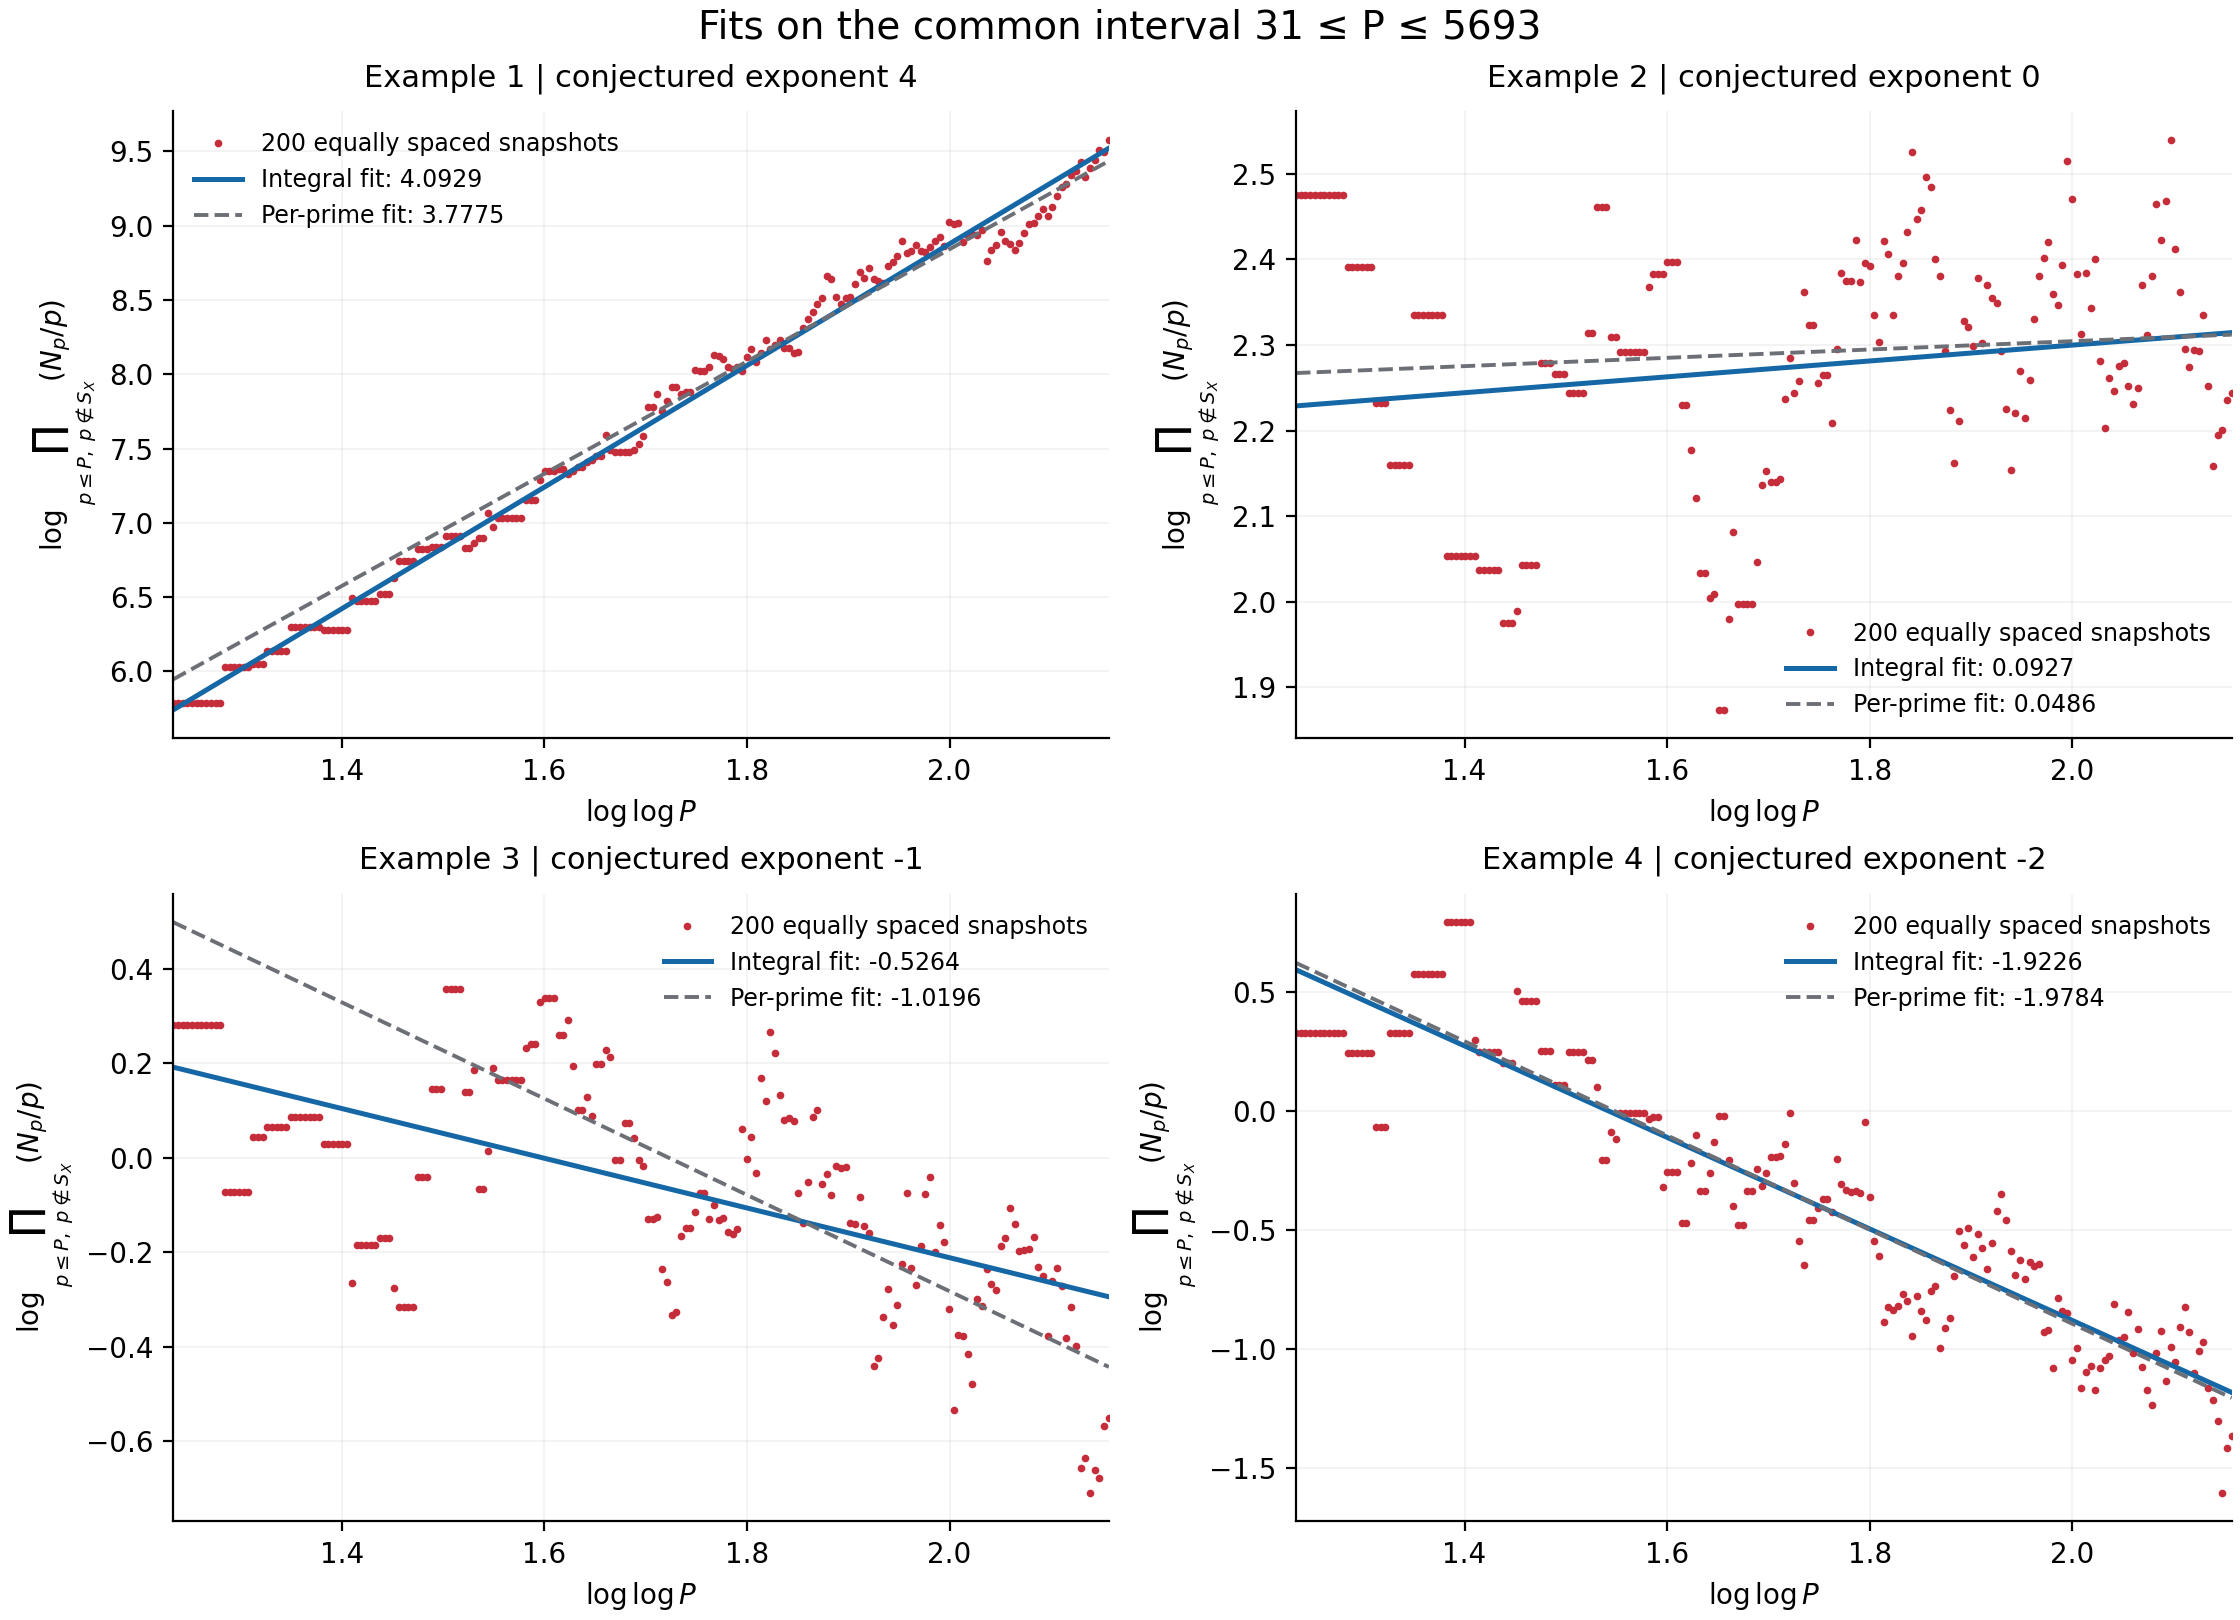

In [3]:
def draw_example(ax, example, x, y, fits, comparison=False):
    a, b = np.log(np.log([P_MIN, P_MAX]))
    snapshots = fits["loglog_snapshots"]
    ax.plot(snapshots["x"], snapshots["y"], ".", color="#c62d3a",
            markersize=3.5, label="%d equally spaced snapshots" % len(snapshots["x"]))
    grid = np.linspace(a, b, 300)
    fit = fits["integral"]
    ax.plot(grid, fit["slope"]*grid + fit["intercept"], color="#1567a5",
            linewidth=1.8, label="Integral fit: %.4f" % fit["slope"])
    if comparison:
        fit = fits["prime"]
        ax.plot(grid, fit["slope"]*grid + fit["intercept"], color="#6c7076",
                linewidth=1.4, linestyle="--", label="Per-prime fit: %.4f" % fit["slope"])
    ax.set_xlabel(r"$\log\log P$")
    ax.set_ylabel(r"$\log\prod_{p\leq P,\ p\notin S_X}(N_p/p)$")
    ax.set_title("Example %d | conjectured exponent %d" %
                 (example["number"], example["expected"]), fontsize=11, pad=9)
    ax.set_xlim(a, b)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.17, linewidth=0.6)
    ax.legend(frameon=False, fontsize=8.5, loc="best")


plt.rcParams.update({'font.size': 10, 'pdf.fonttype': 42})
fig, axes = plt.subplots(2, 2, figsize=(11.2, 8.1), layout='constrained')
for example, result, ax in zip(EXAMPLES, results, axes.flat):
    row = DATA[str(example['number'])]
    x, y = values_from_counts(row['primes'], row['counts'])
    draw_example(ax, example, x, y, result, comparison=True)
fig.suptitle('Fits on the common interval %g <= P <= %g' % (P_MIN, P_MAX), fontsize=14)
# Uncomment to export this figure:
# fig.savefig('fit_comparison.pdf')
plt.show()


## Sensitivity checks

Vary the lower cutoff and snapshot density without selecting parameters to force the conjectured exponent.

In [4]:
print('Exact integral slopes as the lower cutoff changes (upper cutoff %g):' % P_MAX)
print('P_min       Example 1    Example 2    Example 3    Example 4')
for lower in [31, 50, 100, 300, 1000]:
    values=[]
    for example in EXAMPLES:
        row=DATA[str(example['number'])]
        x,y=values_from_counts(row['primes'],row['counts'])
        a,b=np.log(np.log([lower,P_MAX]))
        values.append(integral_fit(x,y,a,b)['slope'])
    print('%5d   ' % lower + ' '.join('%12.6f'%v for v in values))
print('\nUniform-loglog snapshot convergence on the main interval:')
for m in [50,100,200,500,1000,10000]:
    values=[]
    for example in EXAMPLES:
        row=DATA[str(example['number'])]
        x,y=values_from_counts(row['primes'],row['counts'])
        a,b=np.log(np.log([P_MIN,P_MAX]))
        values.append(snapshot_fit(x,y,a,b,m,'loglog')['slope'])
    print('%5d   ' % m + ' '.join('%12.6f'%v for v in values))


Exact integral slopes as the lower cutoff changes (upper cutoff 5693):
P_min       Example 1    Example 2    Example 3    Example 4
   31       4.092944     0.092654    -0.526438    -1.922567
   50       4.066807     0.284634    -0.573899    -2.174388
  100       3.970448     0.174728    -1.013117    -1.867790
  300       3.492445    -0.137117    -1.218702    -1.882468
 1000       2.925945    -0.077027    -1.367954    -2.268356

Uniform-loglog snapshot convergence on the main interval:
   50       4.118741     0.060791    -0.557138    -1.936752
  100       4.104411     0.081063    -0.545247    -1.939799
  200       4.090782     0.090620    -0.536564    -1.928228
  500       4.093265     0.088962    -0.530060    -1.920911
 1000       4.092058     0.091170    -0.528868    -1.922813
10000       4.092816     0.092506    -0.526474    -1.922587


In [5]:
print('Reproduction of the original [10:] convention:')
for example in EXAMPLES:
    row=DATA[str(example['number'])]
    x,y=values_from_counts(row['primes'],row['counts'])
    slope,intercept=np.polyfit(x[10:],y[10:],1)
    print('Example %d: first fitted prime %d; slope %.9f' %
          (example['number'],row['primes'][10],slope))


Reproduction of the original [10:] convention:
Example 1: first fitted prime 31; slope 3.777527693
Example 2: first fitted prime 31; slope 0.048563937
Example 3: first fitted prime 43; slope -1.068952681
Example 4: first fitted prime 41; slope -2.003783455


## Interpretation and checks

All original notebook slopes are reproduced within $5\times10^{-9}$. The first fitted primes in those notebooks are 31, 31, 43 and 41; using a cutoff of 31 for all examples corrects this small mismatch with the paper.

The new slopes are approximately $4.093$, $0.093$, $-0.526$, and $-1.923$. **Do not describe these finite-range fits as statistically unbiased, or as automatically more stable.** Uniform horizontal weighting removes prime-density overrepresentation. It does not remove arithmetic oscillations or finite-range effects. Example 3 is particularly sensitive: starting at 100 gives about $-1.013$, whereas starting at 31 gives about $-0.526$. The lower cutoff should be stated and not selected to obtain a preferred slope.

The product always accumulates every admissible prime, including those before the fitting window. Only observation locations and regression weights change. Bad primes give no jump. An upper-endpoint jump affects a snapshot but has measure zero in the integral; this is intentional.

For step intervals $[l_i,r_i)$, put $w_i=r_i-l_i$, $m_i=(l_i+r_i)/2$, $L=b-a$, $c=(a+b)/2$. Then
\[
\bar Y=\frac1L\sum_i w_iY_i,\qquad
\widehat\beta=\frac{12}{L^3}\sum_iw_i(m_i-c)(Y_i-\bar Y),\qquad
\widehat\alpha=\bar Y-c\widehat\beta.
\]
These are exact integrals of a step function, rather than a trapezoidal approximation. Ordinary weighted OLS at the interval midpoints has a slightly different denominator.

The bundled test file checks this against an independent jump-sum formula, single-jump examples, clipped windows, endpoint conventions and convergence of dense snapshots. The raw counts were computed by exact residue enumeration in Python, including the points at infinity. Small-prime counts were checked by exhaustive $(x,y)$ enumeration. The optional SageMath path below retains the original counting backend; it was not executed in the preparation environment because SageMath was unavailable.


## Optional: recompute using SageMath

Use a SageMath kernel, set the switch to `True`, and execute this cell. The default only uses the embedded cached data.

In [6]:
def compute_with_sage(example, n_primes=750):
    from sage.all import QQ, GF, PolynomialRing, HyperellipticCurve, Primes
    R = PolynomialRing(QQ, "x")
    curve = HyperellipticCurve(R(example["f"]), R(example["h"]))
    primes, counts, omitted = [], [], []
    for sage_p in Primes()[:n_primes]:
        p = int(sage_p)
        if p in example["bad"]:
            omitted.append((p, "bad reduction"))
            continue
        # Unexpected errors intentionally propagate instead of silently
        # removing valid factors from the product.
        count = int(curve.change_ring(GF(p)).cardinality())
        if count == 0:
            omitted.append((p, "zero point count"))
            continue
        primes.append(p)
        counts.append(count)
    return primes, counts, omitted


RECOMPUTE_WITH_SAGE = False
if RECOMPUTE_WITH_SAGE:
    for example in EXAMPLES:
        p, n, omitted = compute_with_sage(example, n_primes=750)
        cached = DATA[str(example['number'])]
        assert p == cached['primes'] and n == cached['counts']
        print(example['number'], 'SageMath agrees with cached counts; omitted:', omitted)
else:
    print('Optional SageMath recomputation is disabled; cached exact counts were used.')


Optional SageMath recomputation is disabled; cached exact counts were used.
